# Part A: Predicting Factory Machine Status (Classification)

## Project Overview

The aim of this project is to build a supervised machine learning model that predicts whether a factory machine is **Working (0)** or **Faulty (1)** using the `factory_data.csv` dataset. Because the target, **Machine Status**, has two classes, this is a **binary classification problem**.

Each record describes one machine's operating conditions: product quality, ambient and process temperature, rotation speed, torque and tool wear. A model that flags faulty machines early lets the factory schedule maintenance *before* a breakdown. However, too many false alarms would cause unnecessary shutdowns.

**Workflow followed in this notebook**

1. **Setup & Data Loading:** importing libraries and inspecting the raw dataset.
2. **Exploratory Data Analysis (EDA):** studying the class imbalance, feature distributions, and how each feature differs between working and faulty machines.
3. **Data Cleaning:** checking duplicates and planning how missing values are handled without data leakage.
4. **Feature Preparation & Engineering:** encoding `Quality`, imputing missing values after the split, and creating `Power` and `Temp_Diff`.
5. **Choosing Algorithms:** selecting five classifiers with different learning approaches.
6. **Training & Testing:** comparing all models against a dummy baseline using precision, recall, F1 and confusion matrices.
7. **Hyperparameter Tuning:** tuning the chosen Random Forest with GridSearchCV.
8. **Feature Importance:** finding which features drive the tuned model's predictions.
9. **Model Improvement:** tuning the Decision Tree with Optuna to test whether it can beat the Random Forest.

## Step 1: Setup & Load Data
### 1.1 Importing Libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & model selection
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# Hyperparameter tuning
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)   # hide per-trial logs for cleaner output

# Consistent plot style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

import warnings
warnings.filterwarnings("ignore")

### 1.2 Loading the Dataset

In [2]:
df = pd.read_csv("C:/Users/yyuel/OneDrive/Documents/Y1 S2/AIML/CA1-Dataset/factory_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (20000, 9)


,Unique ID,Product ID,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
0,1,K12965,M,24.95,35.45,1551.0,42.8,0,0
1,2,Z62710,L,25.05,35.55,1408.0,46.3,3,0
2,3,T20224,L,24.95,35.35,1498.0,49.4,5,0
3,4,Z33024,L,25.05,35.45,1433.0,39.5,7,0
4,5,Z52839,L,25.05,35.55,1408.0,40.0,9,0


The dataset contains **20,000 machine records** and **9 columns**: two identifiers (`Unique ID`, `Product ID`), one categorical feature (`Quality`), five numerical sensor readings and the target `Machine Status`.

### 1.3 Data Types & Summary Statistics

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unique ID             20000 non-null  int64  
 1   Product ID            20000 non-null  object 
 2   Quality               19009 non-null  object 
 3   Ambient T (C)         20000 non-null  float64
 4   Process T (C)         19600 non-null  float64
 5   Rotation Speed (rpm)  18812 non-null  float64
 6   Torque (Nm)           20000 non-null  float64
 7   Tool Wear (min)       20000 non-null  int64  
 8   Machine Status        20000 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 1.4+ MB


In [4]:
df.describe().round(2)

,Unique ID,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
count,20000.00,20000.00,19600.00,18812.00,20000.00,20000.00,20000.00
mean,10000.50,26.90,36.90,1538.80,39.99,107.95,0.03
std,5773.65,2.00,1.48,178.67,9.97,63.65,0.18
min,1.00,22.15,32.55,1168.00,3.80,0.00,0.00
25%,5000.75,25.25,35.75,1423.00,33.20,53.00,0.00
50%,10000.50,26.95,36.95,1503.00,40.10,108.00,0.00
75%,15000.25,28.45,37.95,1613.00,46.80,162.00,0.00
max,20000.00,31.45,40.75,2886.00,76.60,253.00,1.00


**Observations**

- `Product ID` and `Quality` are text columns. `Quality` (L / M / H) must be encoded before modelling, and `Product ID` is just an identifier.
- **Three columns have missing values:** `Quality`, `Process T (C)` and `Rotation Speed (rpm)`. These are handled in Step 4.
- Ambient temperature (22–31°C) and process temperature (33–41°C) vary within narrow ranges.
- Rotation speed has a median of **1,503 rpm** but a maximum of **2,886 rpm**, which suggests a long tail of unusually fast machines.
- Tool wear ranges from **0 to 253 minutes**.
- The mean of `Machine Status` is **0.034**, so only about **3.4% of machines are faulty**.

## Step 2: Exploratory Data Analysis (EDA)
### 2.1 Target Variable: Class Imbalance

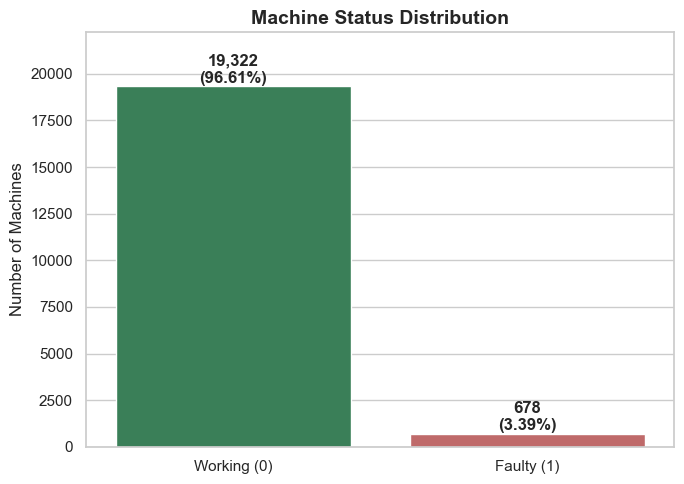

In [5]:
counts = df["Machine Status"].value_counts().sort_index()
pct = df["Machine Status"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=["Working (0)", "Faulty (1)"], y=counts.values, palette=["seagreen", "indianred"])
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + 200, f"{c:,}\n({p:.2f}%)", ha="center", fontweight="bold")
plt.title("Machine Status Distribution", fontsize=14, fontweight="bold")
plt.ylabel("Number of Machines")
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

The dataset is **highly imbalanced**: **19,322 working machines (96.61%)** and only **678 faulty machines (3.39%)**.

This has two important consequences for modelling:

- **Accuracy is misleading.** A model that always predicts "Working" would already be 96.6% accurate while catching **zero** faulty machines. Models are therefore compared mainly on **precision, recall and F1** for the Faulty class.
- **Models may ignore the minority class.** To counter this, the train–test split is **stratified** and the models use `class_weight="balanced"` where available, which gives faulty machines more weight during training.

### 2.2 Distribution of Numerical Features

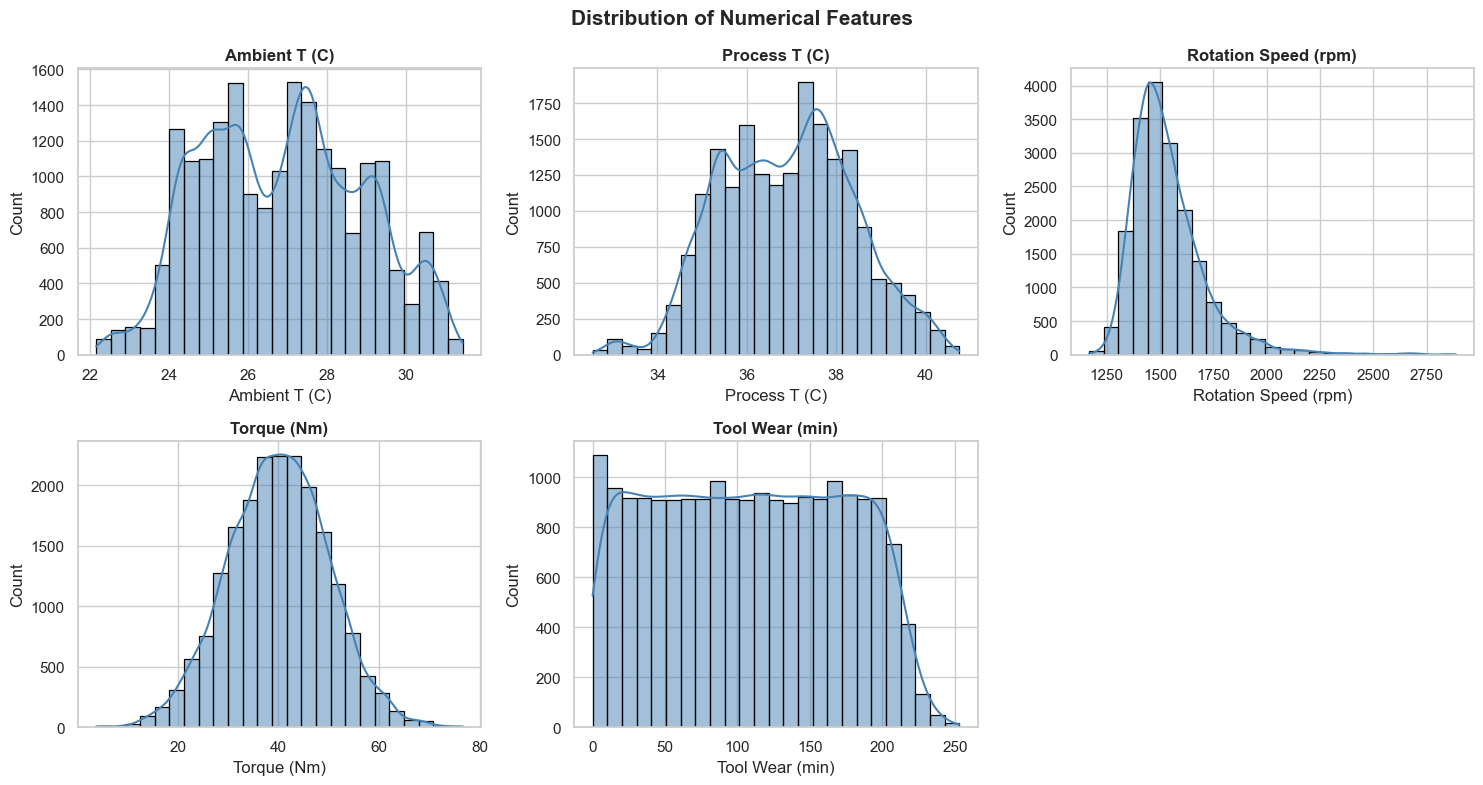

In [6]:
num_cols = ["Ambient T (C)", "Process T (C)", "Rotation Speed (rpm)", "Torque (Nm)", "Tool Wear (min)"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col].dropna(), bins=25, kde=True, ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(col, fontsize=12, fontweight="bold")
fig.delaxes(axes[-1])
plt.suptitle("Distribution of Numerical Features", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

- **Ambient T:** spread fairly evenly between about **24°C and 30°C**, with no clear single peak.
- **Process T:** roughly bell-shaped and centred around **36–38°C**.
- **Rotation Speed:** strongly **right-skewed**. Most machines run at **1,350–1,650 rpm**, but a long tail reaches about **2,900 rpm**.
- **Torque:** close to a **normal distribution** centred around **40 Nm**, with a few very low values (below 10 Nm) and very high values (above 70 Nm).
- **Tool Wear:** almost **uniform from 0 to about 210 minutes**, then drops sharply. This suggests tools are usually replaced at around 200–220 minutes.

### 2.3 Numerical Features by Machine Status

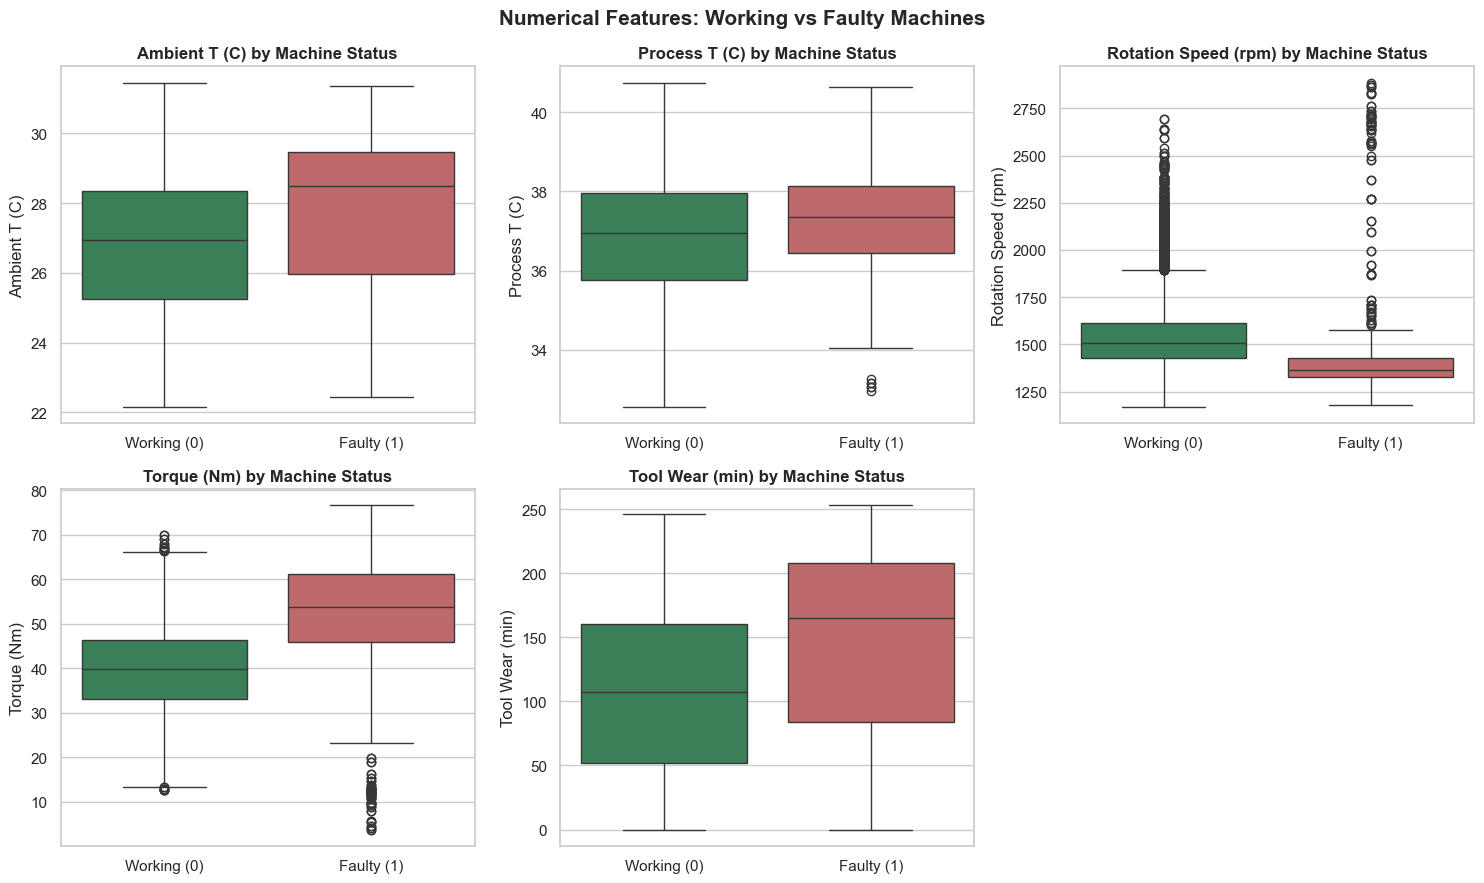

,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min)
Machine Status,,,,,
Working (median),27.0,37.0,1507.0,39.9,107.0
Faulty (median),28.5,37.4,1365.0,53.7,165.0


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Machine Status", y=col, ax=ax, palette=["seagreen", "indianred"])
    ax.set_xticklabels(["Working (0)", "Faulty (1)"])
    ax.set_title(f"{col} by Machine Status", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
fig.delaxes(axes[-1])
plt.suptitle("Numerical Features: Working vs Faulty Machines", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

df.groupby("Machine Status")[num_cols].median().round(1).rename(index={0: "Working (median)", 1: "Faulty (median)"})

| Feature | Median: Working vs Faulty | Interpretation |
|---|---|---|
| **Torque** | **39.9 vs 53.7 Nm** (faulty much higher) | The clearest difference. Faulty machines are working under **heavier mechanical load**. A small group of faulty machines also has very **low** torque (below 20 Nm), which may be a different failure type. |
| **Rotation Speed** | **1,507 vs 1,365 rpm** (faulty lower) | Most faulty machines run slower, but some run **extremely fast (above 2,500 rpm)**, so failures happen at both extremes. |
| **Tool Wear** | **107 vs 165 min** (faulty higher) | Faulty machines tend to have more worn tools. Half of all faulty machines have more than 165 minutes of wear. |
| **Ambient T** | **27.0 vs 28.5°C** (faulty higher) | A moderate difference. Faulty machines tend to run in warmer conditions. |
| **Process T** | **37.0 vs 37.4°C** (faulty slightly higher) | Very small difference. |

**Torque, rotation speed and tool wear** separate the two classes most clearly, so they are expected to be the strongest predictors. Temperature has a weaker effect. Because failures happen at *both* high and low torque and speed, the relationship is **non-linear**, which tree-based models handle well.

### 2.4 Quality Type and Failure Rate

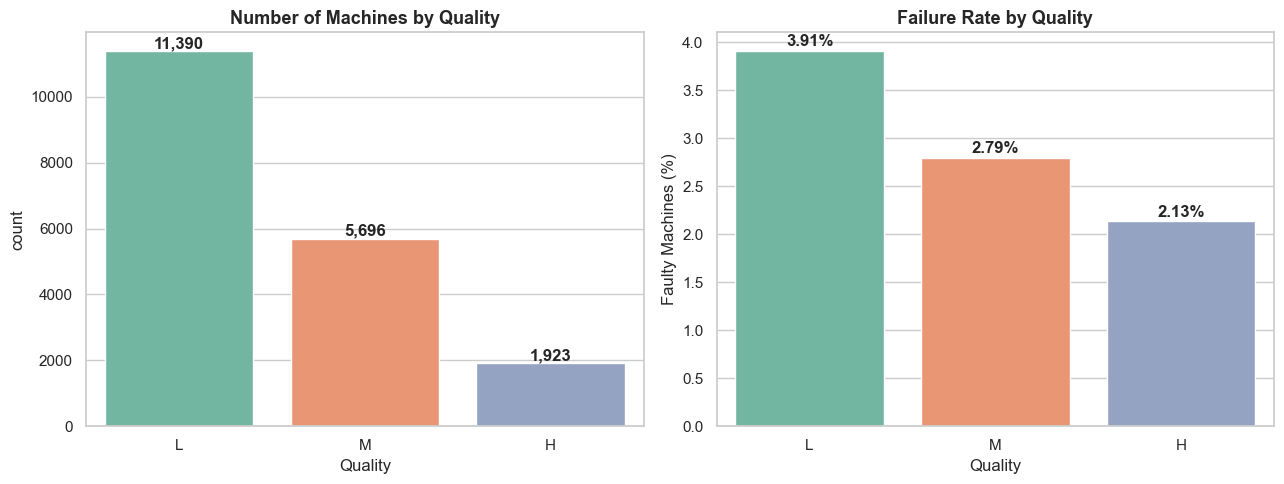

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = ["L", "M", "H"]

sns.countplot(data=df, x="Quality", order=order, ax=axes[0], palette="Set2")
axes[0].set_title("Number of Machines by Quality", fontsize=13, fontweight="bold")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontweight="bold")

fail_rate = df.groupby("Quality")["Machine Status"].mean().reindex(order) * 100
sns.barplot(x=fail_rate.index, y=fail_rate.values, ax=axes[1], palette="Set2")
axes[1].set_title("Failure Rate by Quality", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Faulty Machines (%)")
for i, v in enumerate(fail_rate.values):
    axes[1].text(i, v + 0.05, f"{v:.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

- **Count:** most machines are **Low (L) quality (11,390)**, followed by **Medium (M) (5,696)** and **High (H) (1,923)**.
- **Failure rate:** failures fall steadily as quality rises: **L = 3.91%**, **M = 2.79%**, **H = 2.13%**. Low-quality machines fail almost **twice as often** as high-quality ones.

Because the quality grades have a natural order (L < M < H), and that order matches the trend in failure rate, `Quality` is **ordinally encoded** in Step 4.

### 2.5 Correlation Between Numerical Features

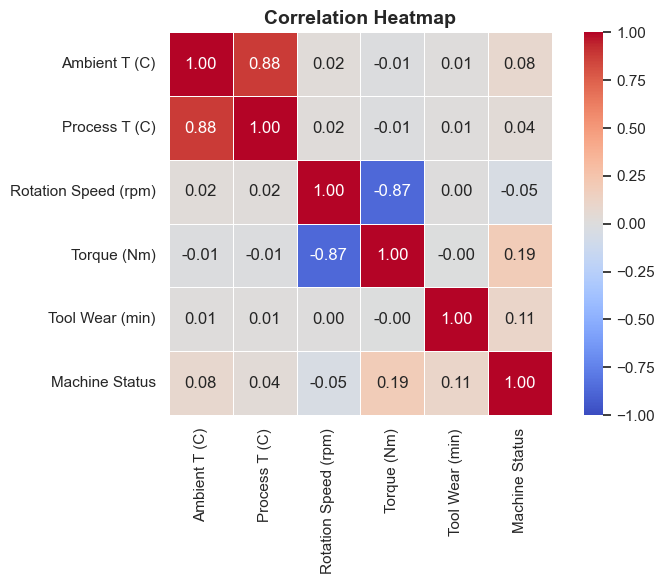

In [9]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["Machine Status"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Two strong relationships stand out:

- **Rotation Speed and Torque are strongly negatively correlated (−0.87).** Faster machines produce less torque, as expected for a machine with roughly constant power. This motivates the engineered **`Power` = Torque × Rotation Speed** feature, which combines the two into one measure of mechanical load.
- **Ambient T and Process T are strongly positively correlated (+0.88).** The process temperature largely follows the room temperature. The **`Temp_Diff` = Process T − Ambient T** feature removes this shared part and isolates the **extra heat the machine itself produces**.

**Tool Wear is uncorrelated with every other feature (about 0.00)**, so it carries independent information.

Correlations with `Machine Status` are weak: **Torque 0.19**, **Tool Wear 0.11**, **Ambient T 0.08**, **Rotation Speed −0.05**. This is expected with only 3.4% faulty machines and non-linear effects (failures at both extremes partly cancel out a linear correlation). It does **not** mean the features are useless.

### EDA Summary

- The target is **highly imbalanced (96.6% working vs 3.4% faulty)**, so accuracy is misleading. Precision, recall and F1 are used instead.
- Faulty machines have **higher torque (53.7 vs 39.9 Nm), lower rotation speed (1,365 vs 1,507 rpm) and more tool wear (165 vs 107 min)** at the median.
- Failures appear at **both extremes** of torque and speed, which suggests non-linear relationships that tree-based models can capture.
- **Low-quality machines fail most often (3.91%)** and high-quality machines least often (2.13%).
- Rotation speed and torque are strongly linked (−0.87), as are the two temperatures (+0.88). This motivates the `Power` and `Temp_Diff` engineered features.

## Step 3: Data Cleaning
### 3.1 Missing Values & Duplicates

In [10]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Missing": missing, "Missing (%)": missing_pct})[missing > 0])
print("\nNumber of duplicate rows:", df.duplicated().sum())

                      Missing  Missing (%)
Quality                   991         4.96
Process T (C)             400         2.00
Rotation Speed (rpm)     1188         5.94

Number of duplicate rows: 0


- **No duplicate rows** were found.
- **Three columns have missing values:** `Rotation Speed (rpm)` (1,188, ≈5.9%), `Quality` (991, ≈5.0%) and `Process T (C)` (400, 2.0%).

Because only a small share of each column is missing, the rows are **kept and the missing values are imputed** instead of dropped. Dropping them would lose up to ~13% of the data, including some of the rare faulty machines.

**Imputation is done *after* the train–test split** (Step 4.3). The median is calculated from the **training set only** and then applied to both sets. If it were calculated from the full dataset, information from the test set would leak into training and make the results look better than they really are.

### 3.2 Removing Non-Predictive Columns

`Unique ID` and `Product ID` are identifiers that are unique to each record. They carry no information about machine health, so they are dropped.

In [11]:
df = df.drop(columns=["Unique ID", "Product ID"])
print("Shape after dropping ID columns:", df.shape)

Shape after dropping ID columns: (20000, 7)


## Step 4: Feature Preparation & Engineering
### 4.1 Encoding Quality
`Quality` has a natural order, so it is **ordinally encoded**: **L = 0, M = 1, H = 2**. Missing values are left as `NaN` here and are filled with the training-set median in Step 4.3, so that no test data is used.

In [12]:
df["Quality"] = df["Quality"].map({"L": 0, "M": 1, "H": 2})
df["Quality"].value_counts(dropna=False)

Quality
0.0    11390
1.0     5696
2.0     1923
NaN      991
Name: count, dtype: int64

### 4.2 Train–Test Split
The data is split into **80% training** and **20% testing**. `stratify=y` keeps the **same 3.4% faulty ratio** in both sets. Without it, the small faulty class could be unevenly split, which would make the test results unreliable.

In [13]:
X = df.drop(columns=["Machine Status"])
y = df["Machine Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape, f"| Faulty: {y_train.mean()*100:.2f}%")
print("Testing set :", X_test.shape, f"| Faulty: {y_test.mean()*100:.2f}%")

Training set: (16000, 6) | Faulty: 3.39%
Testing set : (4000, 6) | Faulty: 3.40%


### 4.3 Imputing Missing Values (after the split)
Missing values are filled with the **median of the training set**. The median is used instead of the mean because `Rotation Speed` is right-skewed, and the median is not pulled up by the extreme high values.

In [14]:
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Missing values after imputation (train):", X_train_imp.isnull().sum().sum())
print("Missing values after imputation (test): ", X_test_imp.isnull().sum().sum())

Missing values after imputation (train): 0
Missing values after imputation (test):  0


### 4.4 Feature Engineering
Two new features are created **after imputation**, so they are calculated from complete values:

| New Feature | Formula | Purpose |
|---|---|---|
| `Power` | Torque × Rotation Speed | Combines the two strongly linked features into one measure of **mechanical load** |
| `Temp_Diff` | Process T − Ambient T | Removes the effect of room temperature and isolates the **heat produced by the machine** |

In [15]:
def add_features(data):
    data = data.copy()
    data["Power"] = data["Torque (Nm)"] * data["Rotation Speed (rpm)"]
    data["Temp_Diff"] = data["Process T (C)"] - data["Ambient T (C)"]
    return data

X_train_imp = add_features(X_train_imp)
X_test_imp = add_features(X_test_imp)

X_train_imp.head()

,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Power,Temp_Diff
12791,2.0,27.35,36.55,1416.0,43.3,66.0,61312.8,9.2
6582,0.0,28.35,37.35,1528.0,35.7,198.0,54549.6,9.0
16873,0.0,27.95,38.35,1478.0,39.5,75.0,58381.0,10.4
11391,0.0,25.85,37.15,2737.0,8.8,142.0,24085.6,11.3
4410,0.0,29.35,37.05,1586.0,32.2,64.0,51069.2,7.7


### 4.5 Feature Scaling
Features are standardised with `StandardScaler` (mean = 0, standard deviation = 1). This is needed for **Logistic Regression, KNN and SVM**, which are sensitive to the size of feature values. Without scaling, `Power` (tens of thousands) would dominate `Temp_Diff` (around 10). Tree-based models do not need scaling, so they use the unscaled data. The scaler is fitted on the training set only.

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

## Step 5: Choosing Algorithms

Five classifiers were chosen to compare different learning approaches:

1. **Logistic Regression:** a simple, interpretable linear model. Used as the linear reference model.
2. **Decision Tree:** learns if-then rules, captures non-linear patterns and is easy to interpret, but it can overfit.
3. **Random Forest:** an ensemble of many decision trees that reduces overfitting, captures non-linear patterns and provides feature importance.
4. **K-Nearest Neighbours (KNN):** classifies a machine based on the most similar machines in the training set. Requires scaled features.
5. **Support Vector Machine (SVM):** finds the boundary that best separates the two classes, and can model non-linear boundaries with the RBF kernel. Requires scaled features.

`class_weight="balanced"` is used for Logistic Regression, Decision Tree, Random Forest and SVM to counter the class imbalance. KNN does not support class weights. A **Dummy Classifier** that always predicts the majority class ("Working") is used as a baseline.

**Evaluation metrics (for the Faulty class)**

| Metric | Question it answers | Why it matters here |
|---|---|---|
| **Precision** | Of the machines flagged as faulty, how many really are? | Low precision means **false alarms** and unnecessary shutdowns |
| **Recall** | Of the truly faulty machines, how many were caught? | Low recall means **missed failures** and unexpected breakdowns |
| **F1** | Balance of precision and recall | Main summary metric for an imbalanced problem |
| **Accuracy** | Overall share of correct predictions | Reported, but misleading because of the imbalance |

## Step 6: Training and Testing
### 6.1 Helper Function for Evaluation

In [17]:
def evaluate(y_true, y_pred):
    """Return accuracy, precision, recall, F1 and confusion-matrix counts."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "TN": tn, "FP (false alarms)": fp, "FN (missed failures)": fn, "TP": tp
    }

metric_fmt = {"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
              "TN": "{:.0f}", "FP (false alarms)": "{:.0f}", "FN (missed failures)": "{:.0f}", "TP": "{:.0f}"}

### 6.2 Dummy Baseline

In [18]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_imp, y_train)
dummy_results = evaluate(y_test, dummy_model.predict(X_test_imp))

pd.DataFrame(dummy_results, index=["Dummy (always Working)"]).style.format(metric_fmt)

,Accuracy,Precision,Recall,F1,TN,FP (false alarms),FN (missed failures),TP
Dummy (always Working),0.9660,0.0000,0.0000,0.0000,3864,0,136,0


The dummy model predicts "Working" for every machine. It reaches **96.6% accuracy** while catching **none of the 136 faulty machines** in the test set (recall = 0, F1 = 0). This shows why accuracy cannot be used to judge models on this dataset. A useful model must achieve **high recall and precision on the Faulty class**.

### 6.3 Logistic Regression

In [19]:
model_lr = LogisticRegression(max_iter=1000, class_weight="balanced")
model_lr.fit(X_train_scaled, y_train)
pred_lr = model_lr.predict(X_test_scaled)
lr_results = evaluate(y_test, pred_lr)

### 6.4 Decision Tree

In [20]:
model_dt = DecisionTreeClassifier(random_state=42, class_weight="balanced")
model_dt.fit(X_train_imp, y_train)
pred_dt = model_dt.predict(X_test_imp)
dt_results = evaluate(y_test, pred_dt)

### 6.5 Random Forest

In [21]:
model_rf = RandomForestClassifier(random_state=42, class_weight="balanced")
model_rf.fit(X_train_imp, y_train)
pred_rf = model_rf.predict(X_test_imp)
rf_results = evaluate(y_test, pred_rf)

# Check for overfitting
print(f"Random Forest training accuracy: {accuracy_score(y_train, model_rf.predict(X_train_imp)):.4f}")
print(f"Random Forest testing accuracy:  {accuracy_score(y_test, pred_rf):.4f}")

Random Forest training accuracy: 0.9999
Random Forest testing accuracy:  0.9935


### 6.6 K-Nearest Neighbours

In [22]:
model_knn = KNeighborsClassifier()
model_knn.fit(X_train_scaled, y_train)
pred_knn = model_knn.predict(X_test_scaled)
knn_results = evaluate(y_test, pred_knn)

### 6.7 Support Vector Machine

In [23]:
model_svm = SVC(class_weight="balanced")
model_svm.fit(X_train_scaled, y_train)
pred_svm = model_svm.predict(X_test_scaled)
svm_results = evaluate(y_test, pred_svm)

### 6.8 Model Comparison

In [24]:
results_base_df = pd.DataFrame({
    "Dummy (always Working)": dummy_results,
    "Logistic Regression": lr_results,
    "Decision Tree": dt_results,
    "Random Forest": rf_results,
    "KNN": knn_results,
    "SVM": svm_results
}).T.sort_values("F1", ascending=False)

results_base_df.style.format(metric_fmt) \
    .highlight_max(subset=["Precision", "Recall", "F1"], color="lightgreen")

,Accuracy,Precision,Recall,F1,TN,FP (false alarms),FN (missed failures),TP
Random Forest,0.9935,1.0000,0.8088,0.8943,3864,0,26,110
Decision Tree,0.9925,0.8955,0.8824,0.8889,3850,14,16,120
KNN,0.9795,0.8214,0.5074,0.6273,3849,15,67,69
SVM,0.9290,0.3141,0.9191,0.4682,3591,273,11,125
Logistic Regression,0.8520,0.1637,0.8162,0.2727,3297,567,25,111
Dummy (always Working),0.9660,0.0000,0.0000,0.0000,3864,0,136,0


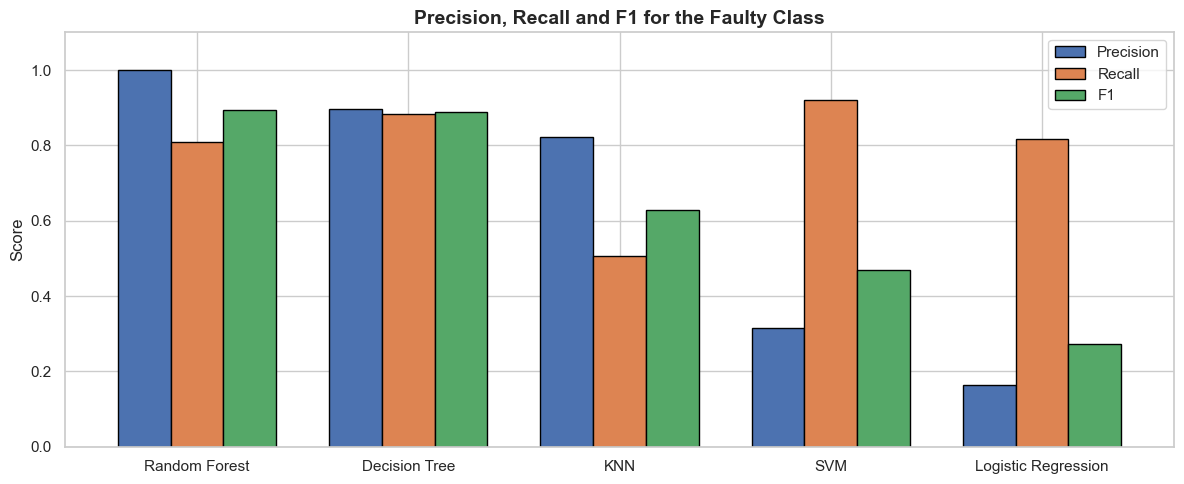

In [25]:
plot_df = results_base_df.drop("Dummy (always Working)")[["Precision", "Recall", "F1"]]

ax = plot_df.plot(kind="bar", figsize=(12, 5), color=["#4c72b0", "#dd8452", "#55a868"], edgecolor="black", width=0.75)
plt.title("Precision, Recall and F1 for the Faulty Class", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

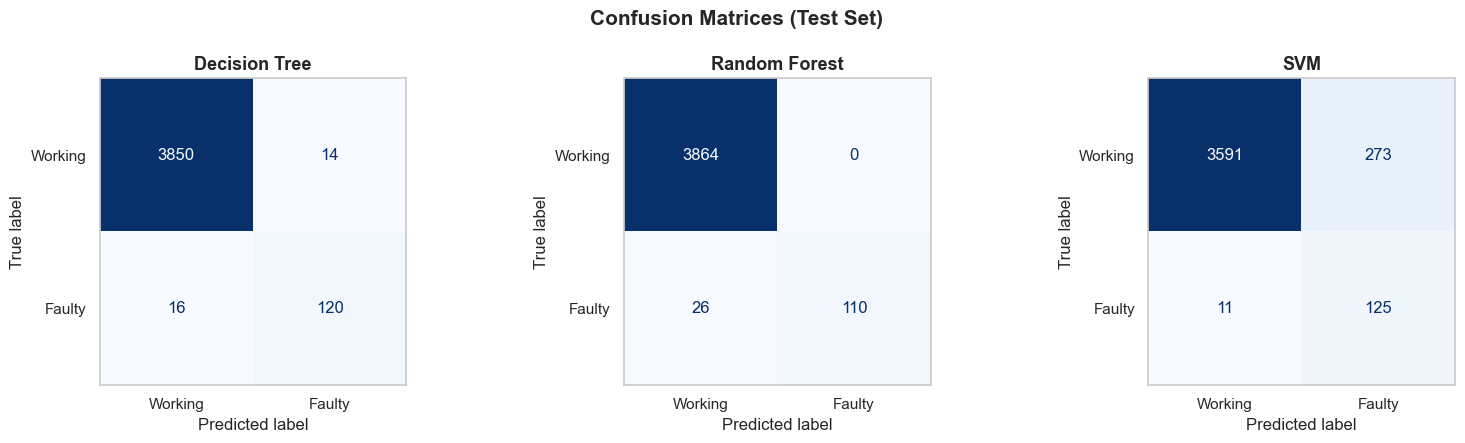

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, [("Decision Tree", pred_dt), ("Random Forest", pred_rf), ("SVM", pred_svm)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Working", "Faulty"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.grid(False)
plt.suptitle("Confusion Matrices (Test Set)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Model Comparison Insights

| Model | Precision | Recall | F1 | False Alarms (FP) | Missed Failures (FN) |
|---|---|---|---|---|---|
| Random Forest | **1.0000** | 0.8088 | **0.8943** | **0** | 26 |
| Decision Tree | 0.8955 | 0.8824 | 0.8889 | 14 | 16 |
| KNN | 0.8214 | 0.5074 | 0.6273 | 15 | 67 |
| SVM | 0.3141 | **0.9191** | 0.4682 | 273 | **11** |
| Logistic Regression | 0.1637 | 0.8162 | 0.2727 | 567 | 25 |
| Dummy | 0.0000 | 0.0000 | 0.0000 | 0 | 136 |

- **Every model beats the dummy baseline**. All of them detect faulty machines, while the dummy detects none.
- **Random Forest (F1 0.894) and Decision Tree (F1 0.889) are clearly the best.** The tree-based models fit the non-linear patterns found in EDA, such as failures at both high and low torque and speed.
- **Random Forest has perfect precision (0 false alarms)** but misses 26 of 136 faulty machines. **Decision Tree** misses only 16 but raises 14 false alarms.
- **SVM catches the most failures (recall 0.919)** but raises **273 false alarms**. **Logistic Regression** raises **567**. In practice this would mean many unnecessary shutdowns.
- **KNN** misses almost half the failures (recall 0.507), because it has no class weighting and the large majority of working machines dominates the neighbours.
- **Overfitting check:** the Random Forest's training accuracy (0.9999) is only slightly above its test accuracy (0.9935), so it generalises well to unseen data.

**Model selected for tuning: Random Forest.** It produces **zero false alarms**, which matters because each false alarm means an unnecessary shutdown. Its recall (0.809) is lower than the Decision Tree's (0.882), but recall can be improved by tuning. As an ensemble of many trees, it is also more stable than a single Decision Tree.

## Step 7: Hyperparameter Tuning (Random Forest, GridSearchCV)

`GridSearchCV` tries every combination of the hyperparameters below and evaluates each one with **5-fold stratified cross-validation on the training set only**. The test set is not used to choose the settings. **F1** is used as the scoring metric because it balances precision and recall for the Faulty class.

| Hyperparameter | Values | Effect |
|---|---|---|
| `n_estimators` | 100, 200 | Number of trees |
| `max_depth` | 5, 10, 20 | Limits how deep each tree grows (controls overfitting) |
| `min_samples_split` | 5, 10 | Minimum samples needed to split a node |
| `min_samples_leaf` | 2, 4 | Minimum samples in each leaf |

In [27]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 20],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 4]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42, class_weight="balanced"),
                       rf_params, cv=cv, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train_imp, y_train)

print("Best parameters:", rf_grid.best_params_)
print(f"Best cross-validated F1: {rf_grid.best_score_:.4f}")

best_rf = rf_grid.best_estimator_
pred_rf_tuned = best_rf.predict(X_test_imp)
rf_tuned_results = evaluate(y_test, pred_rf_tuned)

rf_compare_df = pd.DataFrame({
    "Random Forest (Base)": rf_results,
    "Random Forest (GridSearch Tuned)": rf_tuned_results
}).T
rf_compare_df.style.format(metric_fmt)

Best parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best cross-validated F1: 0.8919


,Accuracy,Precision,Recall,F1,TN,FP (false alarms),FN (missed failures),TP
Random Forest (Base),0.9935,1.0000,0.8088,0.8943,3864,0,26,110
Random Forest (GridSearch Tuned),0.9950,0.9833,0.8676,0.9219,3862,2,18,118


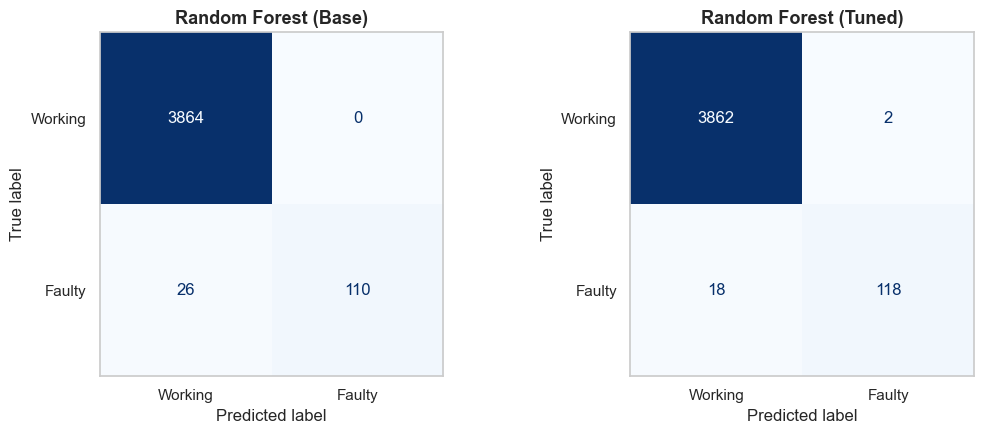

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [("Random Forest (Base)", pred_rf), ("Random Forest (Tuned)", pred_rf_tuned)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Working", "Faulty"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.grid(False)
plt.tight_layout()
plt.show()

### Tuning Insights

**Best parameters:** `n_estimators=100`, `max_depth=20`, `min_samples_split=5`, `min_samples_leaf=2` (cross-validated F1 = **0.892**).

| | Precision | Recall | F1 | False Alarms (FP) | Missed Failures (FN) |
|---|---|---|---|---|---|
| Random Forest (Base) | 1.0000 | 0.8088 | 0.8943 | 0 | 26 |
| Random Forest (Tuned) | 0.9833 | **0.8676** | **0.9219** | 2 | **18** |

- **Recall improved from 0.809 to 0.868.** The tuned model catches **8 more faulty machines** (missed failures drop from 26 to 18).
- **Precision dropped only slightly, from 1.000 to 0.983**, because the tuned model raised **2 false alarms** out of 3,864 working machines.
- **F1 improved from 0.894 to 0.922**, so the tuned model has a better overall balance.
- Requiring at least 5 samples to split a node and 2 per leaf stops the trees from memorising individual machines. This helps the forest find more of the faulty patterns without adding many false alarms.

For a factory, 8 extra failures caught in exchange for 2 extra false alarms is a clear improvement, because a missed failure (an unexpected breakdown) usually costs far more than an unnecessary inspection.

## Step 8: Feature Importance

Feature importance is taken from the **tuned Random Forest** (the final chosen model). Each score shows how much a feature reduces impurity across all trees, averaged over the forest. Higher scores mean the feature is used more often and more effectively to separate working from faulty machines.

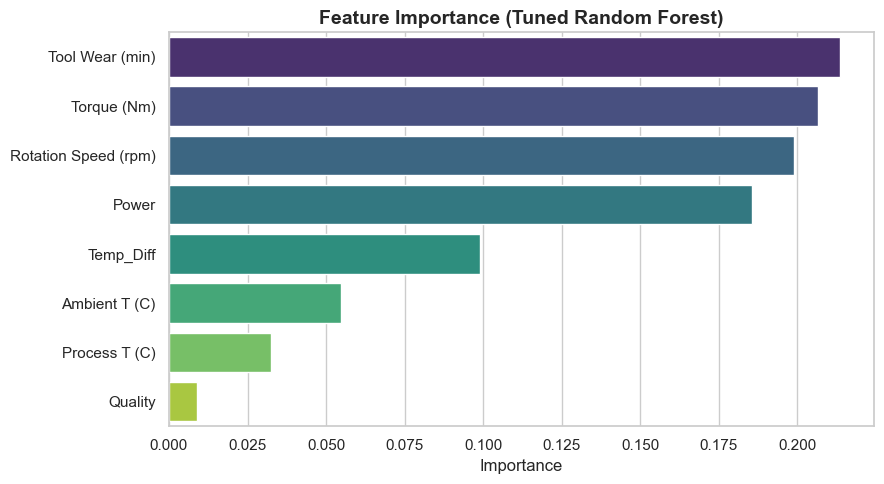

,Feature,Importance
0,Tool Wear (min),0.2137
1,Torque (Nm),0.2065
2,Rotation Speed (rpm),0.1990
3,Power,0.1854
4,Temp_Diff,0.0989
5,Ambient T (C),0.0548
6,Process T (C),0.0326
7,Quality,0.0091


In [29]:
feat_imp = pd.DataFrame({
    "Feature": X_train_imp.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp, x="Importance", y="Feature", palette="viridis")
plt.title("Feature Importance (Tuned Random Forest)", fontsize=14, fontweight="bold")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

feat_imp.style.format({"Importance": "{:.4f}"})

### Feature Importance Insights

| Rank | Feature | Importance |
|---|---|---|
| 1 | Tool Wear (min) | 0.2137 |
| 2 | Torque (Nm) | 0.2065 |
| 3 | Rotation Speed (rpm) | 0.1990 |
| 4 | Power | 0.1854 |
| 5 | Temp_Diff | 0.0989 |
| 6 | Ambient T (C) | 0.0548 |
| 7 | Process T (C) | 0.0326 |
| 8 | Quality | 0.0091 |

- **Four features carry most of the weight.** **Tool Wear, Torque, Rotation Speed and Power** each score about 0.19–0.21, and together they make up about **80%** of the total importance. This matches the EDA, where these features showed the biggest differences between working and faulty machines.
- **Tool Wear ranks first** even though its correlation with Machine Status was only 0.11. A tree can learn threshold rules (for example, "fails more often above roughly 200 minutes"), which a linear correlation does not capture.
- **The engineered `Power` feature ranks 4th**, which confirms that combining torque and speed into one measure of mechanical load is useful.
- **`Temp_Diff` (0.099) is more useful than either raw temperature** (0.055 and 0.033), so isolating the heat produced by the machine was a better feature than the temperatures themselves.
- **Quality contributes almost nothing (0.009)**. Its effect on failure rate (3.91% vs 2.13%) is small compared with the mechanical features.

## Step 9: Model Improvement (Decision Tree with Optuna)

In the baseline comparison, the Decision Tree had **higher recall** than the Random Forest. To check whether the Random Forest was the right choice, the Decision Tree is tuned with **Optuna** to see whether it can match or beat the tuned Random Forest.

To make it a fair comparison with GridSearchCV, each Optuna trial is scored with **5-fold stratified cross-validation F1 on the training set only**. The test set is used only once, for the final evaluation. A fixed sampler seed makes the result reproducible.

In [30]:
def objective(trial):
    params = {
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("max_depth", 3, 40),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"]),
        "splitter": trial.suggest_categorical("splitter", ["best", "random"]),
    }
    model = DecisionTreeClassifier(**params, class_weight="balanced", random_state=42)
    return cross_val_score(model, X_train_imp, y_train, cv=cv, scoring="f1").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=50)

print("Best parameters:", study.best_params)
print(f"Best cross-validated F1: {study.best_value:.4f}")

Best parameters: {'criterion': 'entropy', 'max_depth': 23, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'splitter': 'best'}
Best cross-validated F1: 0.8334


In [31]:
best_dt = DecisionTreeClassifier(**study.best_params, class_weight="balanced", random_state=42)
best_dt.fit(X_train_imp, y_train)
pred_dt_tuned = best_dt.predict(X_test_imp)
dt_tuned_results = evaluate(y_test, pred_dt_tuned)

final_compare_df = pd.DataFrame({
    "Decision Tree (Base)": dt_results,
    "Decision Tree (Optuna)": dt_tuned_results,
    "Random Forest (Base)": rf_results,
    "Random Forest (GridSearch Tuned)": rf_tuned_results
}).T.sort_values("F1", ascending=False)

final_compare_df.style.format(metric_fmt) \
    .highlight_max(subset=["Precision", "Recall", "F1"], color="lightgreen")

,Accuracy,Precision,Recall,F1,TN,FP (false alarms),FN (missed failures),TP
Random Forest (GridSearch Tuned),0.9950,0.9833,0.8676,0.9219,3862,2,18,118
Decision Tree (Optuna),0.9942,0.9449,0.8824,0.9125,3857,7,16,120
Random Forest (Base),0.9935,1.0000,0.8088,0.8943,3864,0,26,110
Decision Tree (Base),0.9925,0.8955,0.8824,0.8889,3850,14,16,120


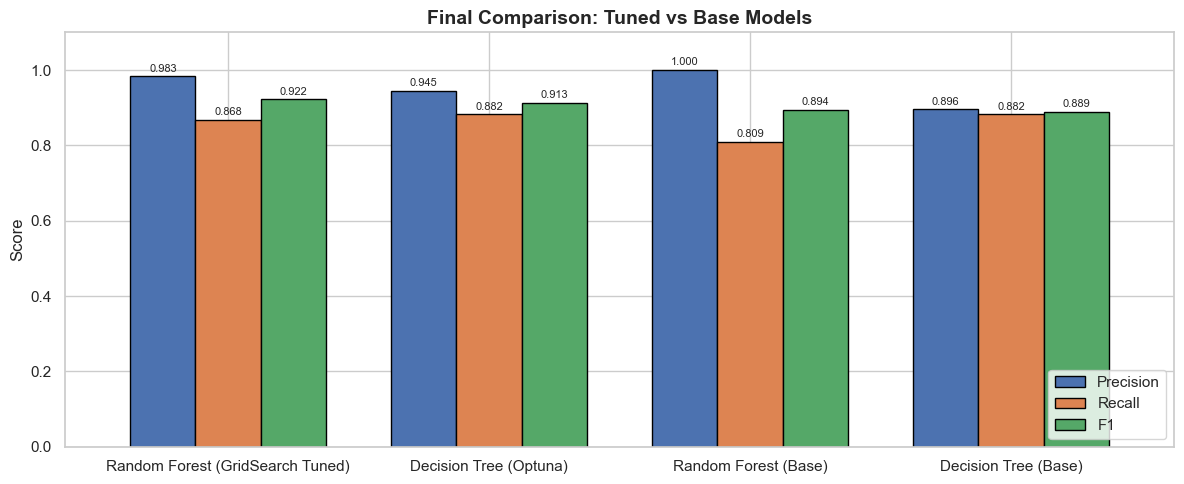

In [32]:
plot_df = final_compare_df[["Precision", "Recall", "F1"]]
ax = plot_df.plot(kind="bar", figsize=(12, 5), color=["#4c72b0", "#dd8452", "#55a868"], edgecolor="black", width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.title("Final Comparison: Tuned vs Base Models", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Improvement Insights

**Optuna best parameters:** `criterion="entropy"`, `max_depth=23`, `max_features="log2"`, `min_samples_split=2`, `min_samples_leaf=1` (cross-validated F1 = **0.833**).

| Model | Precision | Recall | F1 | False Alarms (FP) | Missed Failures (FN) |
|---|---|---|---|---|---|
| **Random Forest (GridSearch Tuned)** | **0.9833** | 0.8676 | **0.9219** | **2** | 18 |
| Decision Tree (Optuna) | 0.9449 | **0.8824** | 0.9125 | 7 | **16** |
| Random Forest (Base) | 1.0000 | 0.8088 | 0.8943 | 0 | 26 |
| Decision Tree (Base) | 0.8955 | 0.8824 | 0.8889 | 14 | 16 |

- **Optuna improved the Decision Tree.** F1 rose from **0.889 to 0.913**, and false alarms were **halved (14 → 7)** while recall stayed at 0.882.
- **The tuned Random Forest is still the best model.** It has the highest F1 (**0.922**) and the fewest false alarms (**2 vs 7**). The tuned Decision Tree catches only **2 more failures** (16 vs 18 missed).
- **The Random Forest is also more reliable.** Its cross-validated F1 (**0.892**) is much higher than the tuned Decision Tree's (**0.833**). The tree's strong test result may partly depend on this particular split, while the forest performed consistently across all 5 folds.

**Final model: Random Forest tuned with GridSearchCV.** The Optuna experiment confirms the original choice. Even a well-tuned single tree does not match the forest's balance of precision, recall and stability.

## Final Conclusion

This project built a complete classification pipeline to predict whether a factory machine is **Working** or **Faulty**, using the `factory_data.csv` dataset.

**EDA** showed that the target is highly imbalanced (**96.6% working vs 3.4% faulty**), so a model that always predicts "Working" already reaches 96.6% accuracy while catching no failures. Models were therefore judged mainly on **precision, recall and F1** for the Faulty class. Faulty machines had **higher torque (53.7 vs 39.9 Nm), lower rotation speed (1,365 vs 1,507 rpm) and more tool wear (165 vs 107 min)** at the median, and failures occurred at both extremes of torque and speed.

For preprocessing, the ID columns were dropped, `Quality` was ordinally encoded, and missing values were imputed with the **training-set median after the split** to avoid data leakage. Two features were engineered: **`Power`** (mechanical load) and **`Temp_Diff`** (heat produced by the machine).

Five classifiers were compared against the dummy baseline. **Random Forest (F1 0.894, 0 false alarms)** and **Decision Tree (F1 0.889)** performed best. Random Forest was selected for its perfect precision and stability, and was tuned with **GridSearchCV**. As a check, the Decision Tree was tuned with **Optuna**. It improved to F1 0.913 but still fell short of the forest.

> **Final model: GridSearch-tuned Random Forest: Precision 0.983, Recall 0.868, F1 0.922. It catches 118 of 136 faulty machines with only 2 false alarms out of 3,864 working machines.**

Feature importance showed that **Tool Wear, Torque, Rotation Speed and the engineered Power feature** drive the predictions (about 80% of total importance), while Quality has almost no effect.

### Limitations & Future Work

- The final model still **misses 18 of 136 faulty machines (13%)**. In a real factory, each missed failure means an unexpected breakdown.
- With only **136 faulty machines in the test set**, each one changes recall by about 0.7 percentage points, so small differences between models (e.g. 16 vs 18 missed) should be read with caution.
- The decision threshold was left at the default 0.5. **Lowering the threshold** could trade a few more false alarms for fewer missed failures, if missed failures are more costly to the factory.
- Resampling methods such as **SMOTE** could be tried as an alternative to `class_weight="balanced"`.
- The small group of faulty machines with **very low torque or very high speed** may be a different failure type. Investigating it separately could improve recall.